# Optimal stopping: envelopes and independent exercise policies

Family 22. Exercise opportunities and the information available at each time
are explicit. The finite-state problem has an exact recursion; regression-based
exercise is approximate and must be evaluated on independent paths.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'convexity').exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from convexity.math import contracts as ct, curves as cv, pricing as pr
rng = np.random.default_rng(2200)
ref, expiry = '2026-01-01', '2027-01-01'
discount, dividend = cv.flat_curve(ref, .04), cv.flat_curve(ref, .01)
model = pr.BlackScholesModel(100., discount, dividend, .2)
plt.rcParams.update({'figure.figsize': (9, 3.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})
print('Interpreter:', sys.executable)

Interpreter: /home/ethan/miniconda3/envs/quant/bin/python


## Inspect an exact Snell envelope

Rows are decision times and columns are states. The exercise region compares
immediate payoff with discounted continuation. Terminal exercise is mandatory.

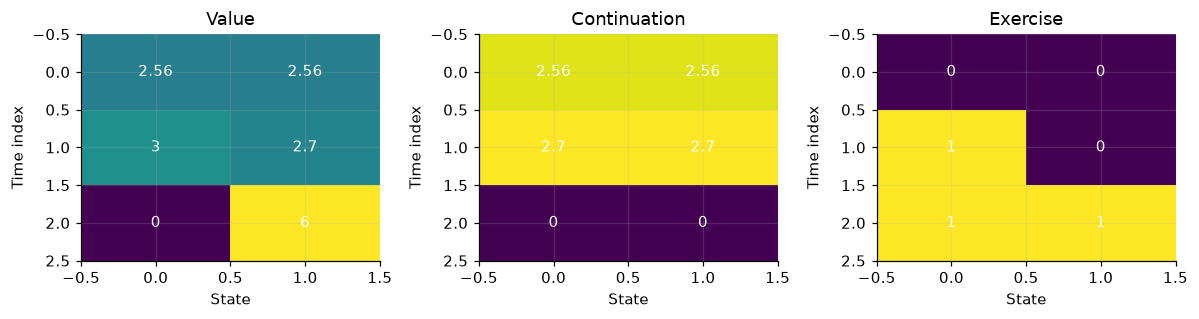

In [2]:
from convexity.math import stopping as st
rewards=np.array([[1.,1.],[3.,0.],[0.,6.]])
transitions=np.tile([[.5,.5],[.5,.5]],(2,1,1))
solution=st.BackwardInduction().solve(st.StoppingProblem(rewards,transitions,.9))
fig,axes=plt.subplots(1,3,figsize=(11,3))
for ax,values,title in zip(axes,[solution.values,solution.continuation,solution.exercise_region],['Value','Continuation','Exercise']):
    ax.imshow(values,aspect='auto');ax.set(title=title,xlabel='State',ylabel='Time index')
    for i in range(3):
        for j in range(2):ax.text(j,i,f'{float(values[i,j]):.3g}',ha='center',va='center',color='white')
plt.tight_layout();plt.show()

## Train and evaluate on separate Q paths

The state is sufficient for this vanilla put. Validation error is conditional
on the learned policy. The European payoff is a useful lower reference; a
binomial American price provides an independent numerical comparison.

,Method,Value,Policy standard error
0,European MC,6.095494,NaN
1,Independent policy MC,6.416457,0.050753
2,American tree,6.402730,NaN


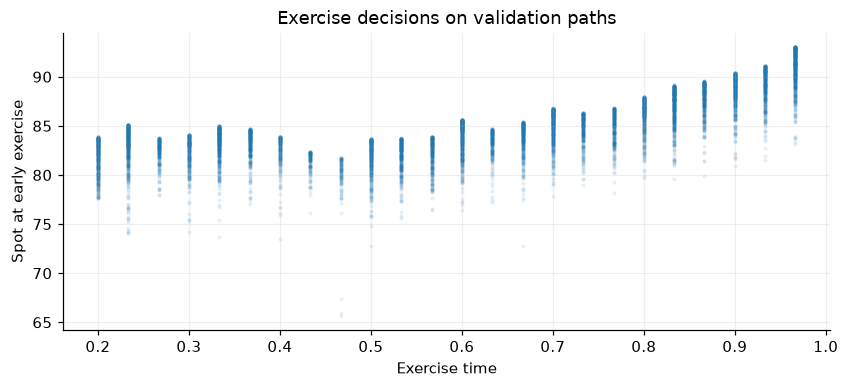

In [3]:
def paths(seed,draws):
    gen=np.random.default_rng(seed);dt=1/30
    logs=np.c_[np.zeros(draws),np.cumsum((.04-.5*.2**2)*dt+.2*np.sqrt(dt)*gen.normal(size=(draws,30)),axis=1)]
    spot=100*np.exp(logs)
    return spot,np.maximum(100-spot,0)
train,train_reward=paths(2201,14000)
validation,reward=paths(2202,22000)
policy=st.least_squares_policy(train,train_reward,np.exp(-.04/30),degree=3)
result=policy.evaluate(validation,reward,np.exp(-.04/30))
stock_model=pr.BlackScholesModel(100,discount,cv.flat_curve(ref,0),.2)
contract=ct.VanillaContract(100,ct.Exercise('american',(ref,expiry)),'put')
reference=pr.price(pr.PricingProblem(contract,stock_model,ref),pr.VanillaEngine('tree',steps=600))
display(pd.DataFrame({'Method':['European MC','Independent policy MC','American tree'],
 'Value':[reward[:,-1].mean()*np.exp(-.04),result.value,reference.value],
 'Policy standard error':[None,result.standard_error,None]}))
tau=result.exercise_indices;early=tau<30
plt.scatter(tau[early]/30,validation[np.arange(len(tau))[early],tau[early]],s=3,alpha=.07)
plt.xlabel('Exercise time');plt.ylabel('Spot at early exercise');plt.title('Exercise decisions on validation paths');plt.show()

## Exercise dates and dividend events

A Bermudan contract has a finite exercise set. Discrete cash dividends are
passed to the finite-difference engine as dated events, rather than smoothed into
a yield.

In [4]:
rows=[]
for style,dates in [('european',(expiry,)),('bermudan',('2026-07-01',expiry)),('american',(ref,expiry))]:
    contract=ct.VanillaContract(100,ct.Exercise(style,dates),'call')
    problem=pr.PricingProblem(contract,stock_model,ref)
    for amount in [0.,4.]:
        divs=() if amount==0 else (ct.CashFlow('2026-07-01',amount),)
        rows.append((style,amount,pr.price(problem,pr.VanillaEngine('fd',steps=200,grid=200,dividends=divs)).value))
display(pd.DataFrame(rows,columns=['Exercise','Cash dividend','Call value']))

,Exercise,Cash dividend,Call value
0,european,0.0,9.926526
1,european,4.0,7.811215
2,bermudan,0.0,9.926526
3,bermudan,4.0,8.046149
4,american,0.0,9.926526
5,american,4.0,8.046149


## Scope of the evidence

These are generated-data experiments under the stated models, not market forecasts or universal model rankings. Numerical errors, backend restrictions and measure assumptions are documented in the [financial catalog](../financial_mathematics.md) and [QA record](../financial_qa.md). Automated adversarial checks live in `tests/math/finance/`.